# 01 — Analyse exploratoire des données (EDA)

**Projet :** pipeline MLOps de prédiction du risque de crédit — *Abdessamad Abouchraa, Master Data & AI*

Ce notebook analyse le jeu **gold**, c'est-à-dire les données réellement utilisées pour l'entraînement : une ligne par
demande de crédit, après validation, déduplication (couche silver) et calcul des variables (couche gold). Il est lu
depuis l'instantané versionné par **DVC** (`data/gold_snapshot/gold.parquet`).

**Objectifs**
1. vérifier la qualité des données (types, valeurs manquantes, doublons, bornes) ;
2. comprendre la variable cible et son déséquilibre ;
3. étudier la distribution des variables et leur lien avec le défaut de paiement ;
4. en tirer les choix de modélisation appliqués dans `jobs/train.py`.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data_loader import load_gold, NUMERIC, NUMERIC_RAW, NUMERIC_DERIVED, CATEGORICAL, TARGET

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}".replace(",", " "))
C0, C1 = "#3b82f6", "#ef4444"          # sans défaut / défaut

df, source = load_gold()
print("Source :", source)
df.head()

Source : instantané gold versionné par DVC (data/gold_snapshot/gold.parquet), 147 257 lignes


,application_id,event_date,age,income,employment_years,loan_amount,loan_term_months,interest_rate,credit_score,num_open_accounts,num_late_payments,debt_to_income,payment_to_income,late_per_account,home_ownership,loan_purpose,label,snapshot_date
0,000212df-d57a-4790-b4b6-e08eabe9f310,2026-11-17,34,34 744.130,7,25 045.770,36,8.670,717,6,1,0.721,0.261,0.143,OWN,car,0,2026-11-17
1,000294a2-77e3-4223-8a4c-6b6ab69d2514,2026-11-17,68,32 465.270,30,19 026.010,48,16.990,795,2,0,0.586,0.171,0.000,MORTGAGE,education,0,2026-11-17
2,0002aa90-902e-4c66-9868-94e44d1e1e14,2026-11-17,45,24 081.010,0,7 164.510,24,13.300,511,3,0,0.298,0.169,0.000,RENT,car,1,2026-11-17
3,0005cb36-cbe4-4dfe-92ee-19e4df995156,2026-11-17,43,8 000.000,35,5 154.200,24,12.050,843,9,0,0.644,0.361,0.000,RENT,debt,0,2026-11-17
4,0006db80-de06-4c92-9b47-d8fdd4879eb3,2026-11-17,30,22 853.950,18,34 748.190,12,11.630,668,11,0,1.520,1.697,0.000,MORTGAGE,debt,1,2026-11-17


## 1. Structure et qualité des données

In [2]:
print(f"{df.shape[0]:,} demandes x {df.shape[1]} colonnes".replace(",", " "))
qualite = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "valeurs manquantes": df.isna().sum(),
    "valeurs distinctes": df.nunique(),
})
qualite

147 257 demandes x 18 colonnes


,type,valeurs manquantes,valeurs distinctes
application_id,object,0,147257
event_date,object,0,1
age,int32,0,58
income,float64,0,140988
employment_years,int32,0,41
loan_amount,float64,0,144477
loan_term_months,int32,0,5
interest_rate,float64,0,1901
credit_score,int32,0,534
num_open_accounts,int32,0,16


In [3]:
print("Doublons sur application_id :", df["application_id"].duplicated().sum())
bornes = df[NUMERIC].agg(["min", "max"]).T
bornes["règle de validation (silver)"] = ""
bornes.loc["age", "règle de validation (silver)"] = "18 ≤ âge ≤ 100"
bornes.loc["income", "règle de validation (silver)"] = "revenu > 0"
bornes.loc["loan_amount", "règle de validation (silver)"] = "montant > 0"
bornes.loc["credit_score", "règle de validation (silver)"] = "300 ≤ score ≤ 850"
bornes

Doublons sur application_id : 0


,min,max,règle de validation (silver)
age,18.000,75.000,18 ≤ âge ≤ 100
income,8 000.000,135 816.520,revenu > 0
employment_years,0.000,40.000,
loan_amount,1 000.460,39 999.790,montant > 0
loan_term_months,12.000,60.000,
interest_rate,3.000,22.000,
credit_score,300.000,850.000,300 ≤ score ≤ 850
num_open_accounts,0.000,15.000,
num_late_payments,0.000,10.000,
debt_to_income,0.010,4.997,


**Constat.** Aucune valeur manquante, aucun doublon d'identifiant, et toutes les valeurs respectent les règles de la
couche silver. Les ~2 % de lignes au revenu manquant et les ~1 % de doublons injectés par le générateur ont donc bien été
écartés en amont (lignes invalides dans `silver/_rejected`, doublons supprimés par `MERGE`). Le jeu gold est prêt pour
l'apprentissage sans imputation.

## 2. Variable cible : le défaut de paiement

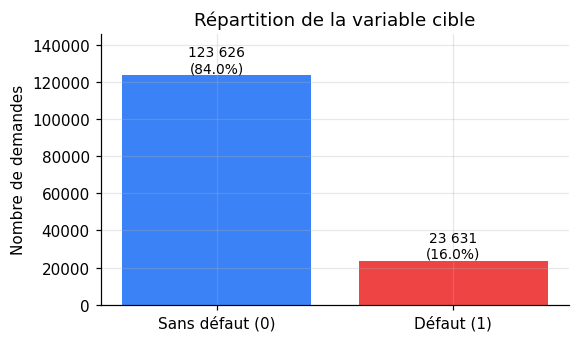

Taux de défaut : 16.05%


In [4]:
counts = df[TARGET].value_counts().sort_index()
rate = df[TARGET].mean()
fig, ax = plt.subplots(figsize=(5.5, 3.2))
bars = ax.bar(["Sans défaut (0)", "Défaut (1)"], counts.values, color=[C0, C1])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / len(df):.1%})".replace(",", " "),
            ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Nombre de demandes"); ax.set_title("Répartition de la variable cible")
ax.set_ylim(0, counts.max() * 1.18)
plt.show()
print(f"Taux de défaut : {rate:.2%}")

**Constat.** La cible est **déséquilibrée** : environ 16 % de défauts. Conséquences pour la modélisation :
- l'*accuracy* serait trompeuse (prédire « jamais de défaut » donnerait 84 %) : on évalue avec l'**AUC ROC** et
  surtout l'**AUC-PR**, sensible à la classe minoritaire ;
- le déséquilibre reste modéré : pas besoin de sur-échantillonnage, les modèles reçoivent la distribution réelle.

## 3. Distribution des variables numériques

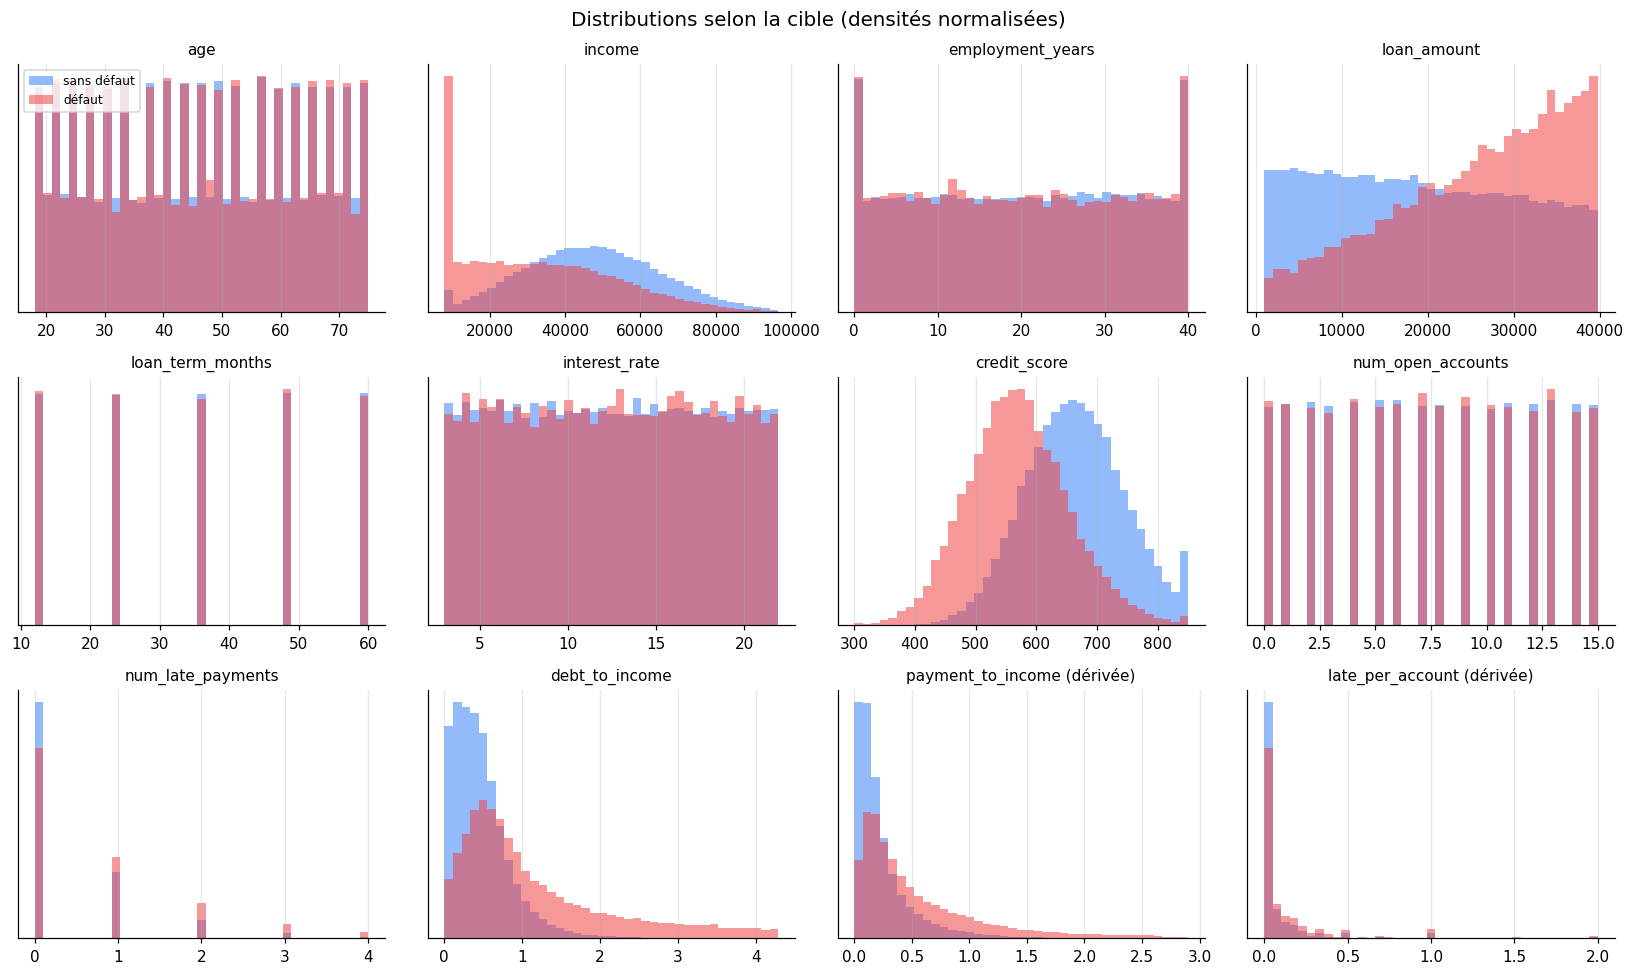

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, col in zip(axes.flat, NUMERIC):
    hi = df[col].quantile(0.995)                       # coupe la longue traîne pour la lisibilité
    data = df[df[col] <= hi]
    bins = np.linspace(data[col].min(), hi, 40)
    ax.hist(data.loc[data[TARGET] == 0, col], bins=bins, density=True, alpha=.55, color=C0, label="sans défaut")
    ax.hist(data.loc[data[TARGET] == 1, col], bins=bins, density=True, alpha=.55, color=C1, label="défaut")
    ax.set_title(col + (" (dérivée)" if col in NUMERIC_DERIVED else ""), fontsize=10)
    ax.set_yticks([])
axes.flat[0].legend(fontsize=8)
fig.suptitle("Distributions selon la cible (densités normalisées)", fontsize=13)
plt.tight_layout(); plt.show()

**Constat.**
- **Fortement discriminantes** : `credit_score` (les défauts ont un score nettement plus bas), `debt_to_income` et
  `payment_to_income` (plus élevés chez les défauts), ainsi que le **revenu** (plus faible chez les défauts, avec un pic
  au plancher de 8 000) et le **montant demandé** (plus élevé chez les défauts) : ce sont les deux composantes du ratio
  d'endettement. `num_late_payments` est discriminante mais plus modérément.
- **Pas discriminantes** : `age`, `employment_years`, `num_open_accounts`, `interest_rate`, `loan_term_months` :
  les deux distributions se superposent exactement.
- `debt_to_income`, `payment_to_income`, `late_per_account` et `num_late_payments` sont **asymétriques à droite**
  (longue traîne), ce qui justifie la standardisation pour la régression logistique.

## 4. Variables catégorielles

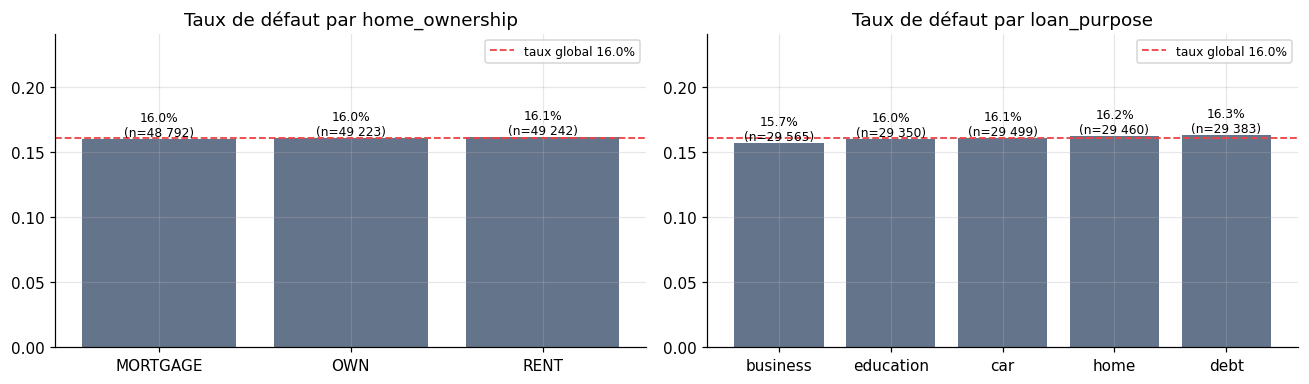

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, col in zip(axes, CATEGORICAL):
    g = df.groupby(col)[TARGET].agg(["mean", "size"]).sort_values("mean")
    ax.bar(g.index, g["mean"], color="#64748b")
    ax.axhline(rate, color=C1, ls="--", lw=1.2, label=f"taux global {rate:.1%}")
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m, f"{m:.1%}\n(n={n:,})".replace(",", " "), ha="center", va="bottom", fontsize=8)
    ax.set_title(f"Taux de défaut par {col}"); ax.set_ylim(0, rate * 1.5); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Constat.** Les modalités sont équilibrées et leur taux de défaut est **quasiment identique au taux global**. Le type
de logement et l'objet du prêt n'apportent donc pas d'information sur le défaut dans ces données. Ils sont conservés
dans le pipeline (encodage *one-hot*), mais on s'attend à des coefficients et des importances proches de zéro.

## 5. Relation entre les variables et le défaut

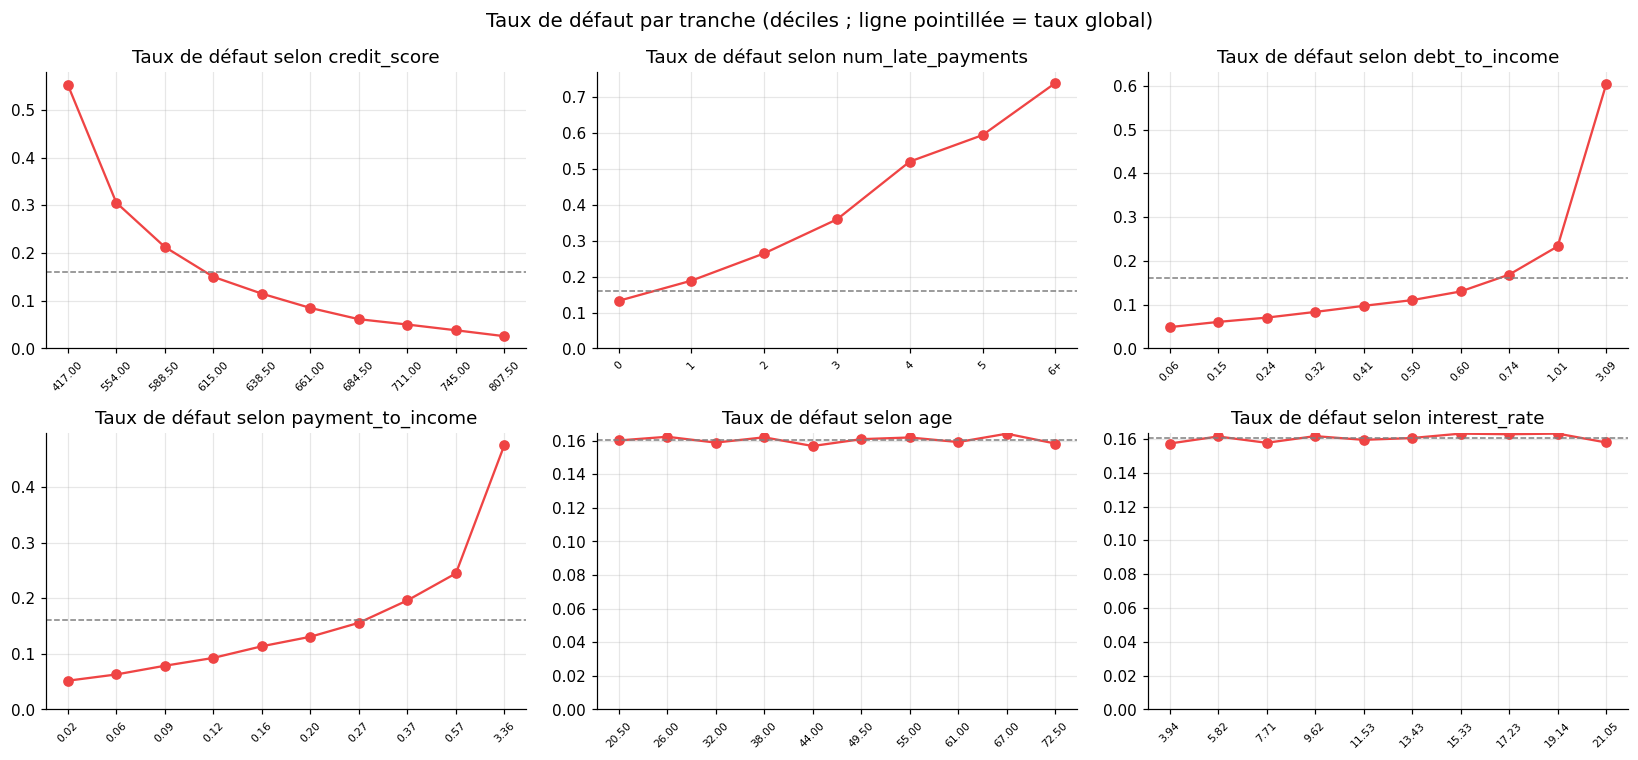

In [7]:
def default_rate_by_bins(col, q=10):
    """Taux de défaut par décile (ou par valeur si peu de valeurs distinctes)."""
    if df[col].nunique() <= 12:
        g = df.groupby(df[col].clip(upper=6))[TARGET].mean()
        return g.index.astype(str).str.replace("6", "6+"), g.values
    bins = pd.qcut(df[col], q=q, duplicates="drop")
    g = df.groupby(bins, observed=True)[TARGET].mean()
    return [f"{iv.mid:,.2f}".replace(",", " ") for iv in g.index], g.values

cols = ["credit_score", "num_late_payments", "debt_to_income", "payment_to_income", "age", "interest_rate"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flat, cols):
    x, y = default_rate_by_bins(col)
    ax.plot(range(len(y)), y, marker="o", color=C1)
    ax.set_xticks(range(len(y))); ax.set_xticklabels(x, rotation=45, fontsize=7)
    ax.axhline(rate, color="gray", ls="--", lw=1)
    ax.set_title(f"Taux de défaut selon {col}"); ax.set_ylim(0, None)
fig.suptitle("Taux de défaut par tranche (déciles ; ligne pointillée = taux global)", fontsize=13)
plt.tight_layout(); plt.show()

**Constat.** Les relations sont **monotones** et très marquées :
- le taux de défaut **chute** quand le score de crédit augmente : environ 55 % dans le premier décile, 2,5 % dans le
  dernier ;
- il **augmente** avec le nombre de retards de paiement (13 % sans retard, 74 % au-delà de 6) et avec l'endettement
  (5 % dans le premier décile de `debt_to_income`, 60 % dans le dernier) ;
- il est **plat** pour l'âge et le taux d'intérêt (≈ 16 % dans toutes les tranches).

Des relations monotones et presque linéaires (sur l'échelle du log-odds) sont exactement le cas où la **régression
logistique** est très performante : cela explique qu'elle rivalise avec GBT et XGBoost dans le pipeline.

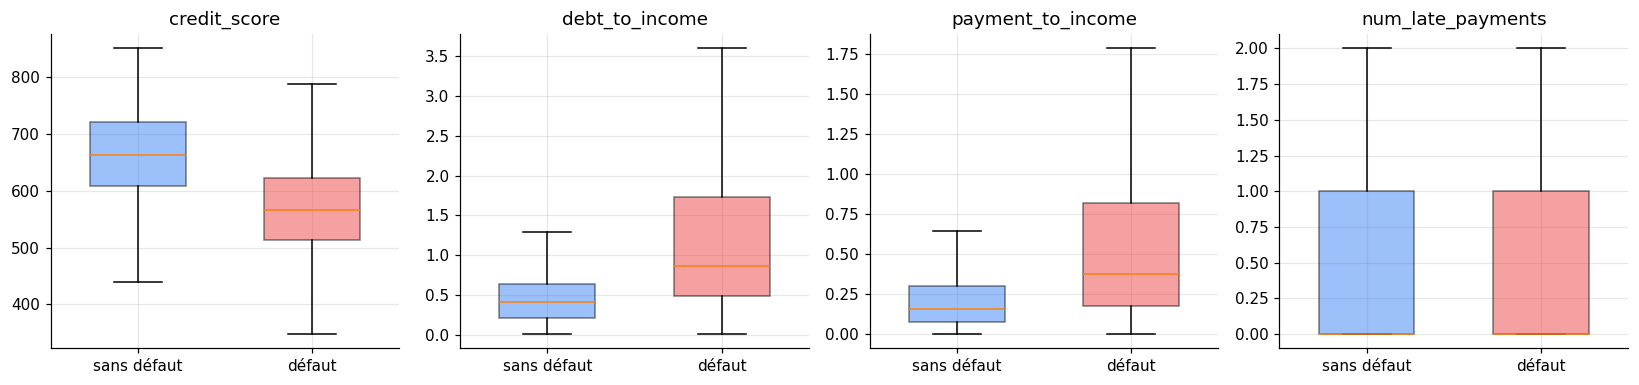

In [8]:
key = ["credit_score", "debt_to_income", "payment_to_income", "num_late_payments"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, col in zip(axes, key):
    data = [df.loc[df[TARGET] == k, col].clip(upper=df[col].quantile(.99)) for k in (0, 1)]
    bp = ax.boxplot(data, tick_labels=["sans défaut", "défaut"], patch_artist=True, widths=.55, showfliers=False)
    for patch, c in zip(bp["boxes"], (C0, C1)):
        patch.set_facecolor(c); patch.set_alpha(.5)
    ax.set_title(col)
plt.tight_layout(); plt.show()

## 6. Corrélations

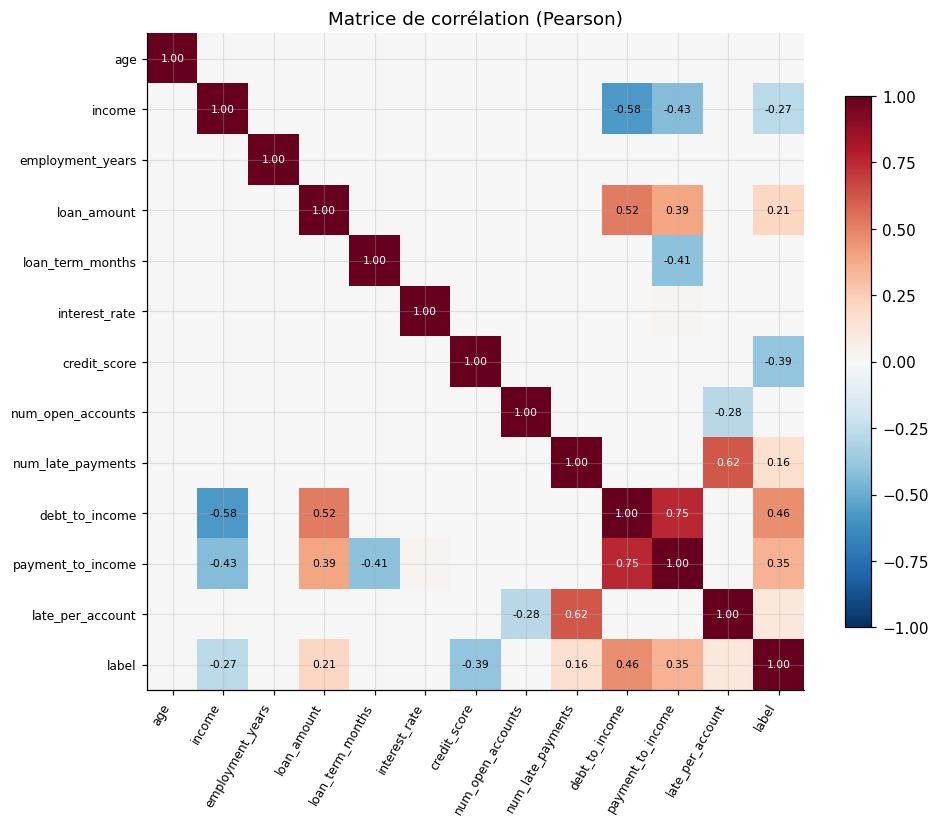

In [9]:
corr = df[NUMERIC + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        if abs(v) >= .15:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > .6 else "black")
fig.colorbar(im, shrink=.8); ax.set_title("Matrice de corrélation (Pearson)")
plt.tight_layout(); plt.show()

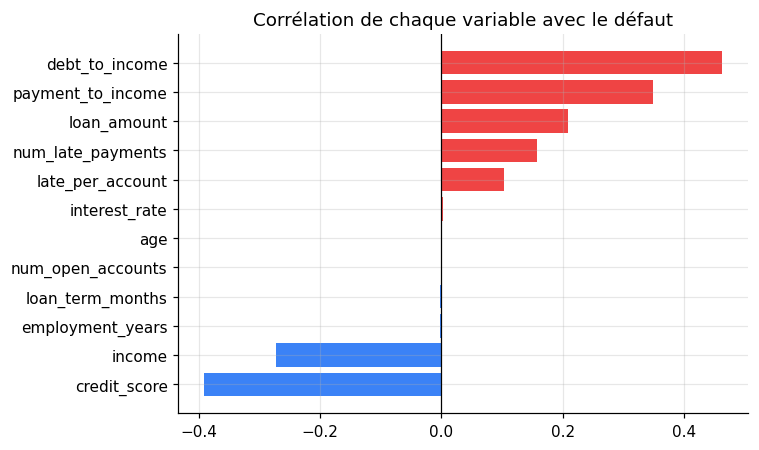

,corrélation avec label
debt_to_income,0.463
credit_score,-0.391
payment_to_income,0.348
income,-0.272
loan_amount,0.209
num_late_payments,0.157
late_per_account,0.103
employment_years,-0.003
loan_term_months,-0.002
interest_rate,0.002


In [10]:
c = corr[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(c.index, c.values, color=[C1 if v > 0 else C0 for v in c.values])
ax.axvline(0, color="black", lw=.8)
ax.set_title("Corrélation de chaque variable avec le défaut")
plt.tight_layout(); plt.show()
c.to_frame("corrélation avec label").sort_values("corrélation avec label", key=abs, ascending=False)

**Constat.**
- Corrélations les plus fortes avec le défaut : `debt_to_income` (+0,46), `credit_score` (−0,39),
  `payment_to_income` (+0,35), puis `income` (−0,27) et `loan_amount` (+0,21). Les retards (`num_late_payments`,
  +0,16) ont une corrélation linéaire plus faible, mais un effet très net sur le taux de défaut (section 5).
- `age`, `employment_years`, `loan_term_months`, `interest_rate` et `num_open_accounts` ont une corrélation nulle.
- **Multicolinéarité** : `debt_to_income` et `payment_to_income` sont fortement corrélées entre elles (toutes deux
  dérivées du montant et du revenu), de même que `num_late_payments` et `late_per_account`. C'est sans conséquence pour
  les arbres ; pour la régression logistique, la **régularisation** (`regParam = 0.01`) et la standardisation stabilisent
  les coefficients.

## 7. Valeurs extrêmes

In [11]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean()

out = pd.DataFrame({"part de valeurs extrêmes (IQR)": df[NUMERIC].apply(iqr_outliers),
                    "taux de défaut parmi elles": [df.loc[(df[c] > df[c].quantile(.75) + 1.5 * (df[c].quantile(.75) - df[c].quantile(.25))), TARGET].mean()
                                                   for c in NUMERIC]})
out.sort_values("part de valeurs extrêmes (IQR)", ascending=False)

,part de valeurs extrêmes (IQR),taux de défaut parmi elles
late_per_account,0.132,0.260
payment_to_income,0.087,0.499
debt_to_income,0.066,0.722
num_late_payments,0.028,0.417
credit_score,0.004,NaN
income,0.003,0.065
age,0.000,NaN
employment_years,0.000,NaN
loan_amount,0.000,NaN
num_open_accounts,0.000,NaN


**Constat.** Les valeurs extrêmes concernent surtout les ratios d'endettement et les retards de paiement. Elles ne sont
**pas des erreurs** (elles respectent les règles de validation) et elles portent un **taux de défaut très élevé** : ce
sont précisément les profils risqués que le modèle doit détecter. Elles sont donc **conservées** ; la standardisation
suffit pour la régression logistique, et les arbres y sont insensibles.

## 8. Conclusions et choix de modélisation

| Constat de l'EDA | Choix dans le pipeline (`jobs/train.py`) |
|---|---|
| Données propres : pas de valeurs manquantes ni de doublons | Pas d'imputation ; la qualité est garantie en amont par la couche silver |
| Cible déséquilibrée (~16 % de défauts) | Évaluation par **AUC** et **AUC-PR**, pas par l'accuracy |
| Relations monotones et quasi linéaires (score, retards, endettement) | **Régression logistique** compétitive ; elle est d'ailleurs le champion |
| Variables asymétriques, échelles très différentes | **StandardScaler** pour la régression logistique (inutile pour les arbres) |
| Variables dérivées corrélées entre elles | **Régularisation** de la régression logistique |
| Variables catégorielles sans signal | Conservées en *one-hot* (`handleInvalid=keep`), importance attendue quasi nulle |
| Valeurs extrêmes = profils à risque | Conservées |

Le notebook `02_analyse_variables_et_baseline.ipynb` mesure le pouvoir prédictif de chaque variable et construit un
modèle de référence pour valider ces conclusions.